# Jupyter Assignment: Altitude-Dependent Design of Converging–Diverging Rocket Nozzles

Week 12 Winter 2026

**Instructions:**  In this assignment, we study the performance of a converging-diverging rocket nozzle using quasi-one-dimensional compressible-flow relations.

Rocket nozzles are used to convert the thermal energy of high-pressure combustion products into directed momentum and thrust. Their performance depends on both nozzle geometry and ambient conditions, so the same nozzle may behave quite differently at sea level and at high altitude. This assignment applies isentropic nozzle relations, the rocket thrust equation, and a standard atmosphere model to examine how area ratio affects exit conditions, thrust, and ideal expansion over a range of altitudes.

Chamber-gas properties are estimated with Cantera for three propellant cases:
- LOX/LH$_2$: liquid oxygen + liquid hydrogen
- LOX/CH$_4$: liquid oxygen + methane
- LOX/C$_2$H$_4$: liquid oxygen + ethylene

The assignment tests the area-Mach relation, isentropic exit-state calculations, choking, thrust prediction, altitude effects, and ideal expansion. The results show how the optimum area ratio shifts to larger values as altitude increases, why a fixed nozzle cannot be ideal over the full flight range, and how overexpanded operation can reduce performance at low altitude.

We will assume the nozzle is choked at the throat and that the flow through the nozzle is quasi-one-dimensional and isentropic. Cantera is used only to estimate chamber properties for each propellant case.

## Imports

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import cantera as ct

## Functions (students are prompted to define these commonly used relations early on)

In [18]:
def area_mach_relation(M, gamma):
    term1 = 2 / (gamma + 1)
    term2 = 1 + (gamma - 1) / 2 * M**2
    power = (gamma + 1) / (2 * (gamma - 1))
    return (1 / M) * (term1 * term2) ** power


def mach_from_area_ratio_supersonic(A_ratio, gamma, M_min=1.0001, M_max=10.0, npts=300000):
    M_grid = np.linspace(M_min, M_max, npts)
    A_grid = area_mach_relation(M_grid, gamma)
    return np.interp(A_ratio, A_grid, M_grid)


def exit_state_from_area_ratio(Ae_At, gamma, R, T0, p0):
    Me = mach_from_area_ratio_supersonic(Ae_At, gamma)
    Te = T0 / (1 + (gamma - 1) / 2 * Me**2)
    pe = p0 / (1 + (gamma - 1) / 2 * Me**2) ** (gamma / (gamma - 1))
    ue = Me * np.sqrt(gamma * R * Te)
    return Me, Te, pe, ue


def throat_mass_flux(p0, T0, gamma, R):
    coeff = np.sqrt(gamma / R) * (2 / (gamma + 1)) ** ((gamma + 1) / (2 * (gamma - 1)))
    return p0 * coeff / np.sqrt(T0)


def thrust(Ae_At, At, p0, T0, gamma, R, p_amb):
    Me, Te, pe, ue = exit_state_from_area_ratio(Ae_At, gamma, R, T0, p0)
    mdot = throat_mass_flux(p0, T0, gamma, R) * At
    Ae = Ae_At * At
    F = mdot * ue + (pe - p_amb) * Ae
    return F, mdot, Me, Te, pe, ue


## 1. a) Use Cantera to determine the chamber gas properties $\gamma$, $R$, $T_0$, and mean molecular weight $M$ for the propellant cases LOX/LH$_2$, LOX/CH$_4$, and LOX/C$_2$H$_4$. Report the results clearly. (2 points)

In [19]:
def get_propellant_properties(fuel, oxidizer='O2', of_mass=6.0, T_react=298.15, p0=3.5e6, mechanism='gri30.yaml'):
    gas = ct.Solution(mechanism)

    MW_f = gas.molecular_weights[gas.species_index(fuel)]
    MW_o = gas.molecular_weights[gas.species_index(oxidizer)]

    n_fuel = 1.0
    m_fuel = n_fuel * MW_f
    m_ox = of_mass * m_fuel
    n_ox = m_ox / MW_o

    gas.TPX = T_react, p0, {fuel: n_fuel, oxidizer: n_ox}
    gas.equilibrate('HP')

    return {
        'fuel': fuel,
        'oxidizer': oxidizer,
        'O/F': of_mass,
        'T0': gas.T,
        'gamma': gas.cp_mass / gas.cv_mass,
        'R': ct.gas_constant / gas.mean_molecular_weight,
        'MW_products': gas.mean_molecular_weight
    }

# Chamber and nozzle inputs
p0 = 3.5e6
p_amb = 101325.0
T_react = 298.15
At = 8.0e-4

propellant_cases = [
    {"label": "LOX/LH2", "fuel": "H2", "oxidizer": "O2", "O/F": 6.0},
    {"label": "LOX/CH4", "fuel": "CH4", "oxidizer": "O2", "O/F": 3.5},
    {"label": "LOX/C2H4", "fuel": "C2H4", "oxidizer": "O2", "O/F": 3.0},
]

propellant_data = {}

for case in propellant_cases:
    props = get_propellant_properties(
        fuel=case['fuel'],
        oxidizer=case['oxidizer'],
        of_mass=case['O/F'],
        T_react=T_react,
        p0=p0
    )
    propellant_data[case['label']] = props

print('Chamber properties:\n')
for label, props in propellant_data.items():
    print(label)
    print(f"  T0    = {props['T0']:.1f} K")
    print(f"  gamma = {props['gamma']:.4f}")
    print(f"  R     = {props['R']:.2f} J/kg-K")
    print(f"  MW    = {props['MW_products']:.3f} kg/kmol")
    print()


Chamber properties:

LOX/LH2
  T0    = 3505.2 K
  gamma = 1.2007
  R     = 632.38 J/kg-K
  MW    = 13.148 kg/kmol

LOX/CH4
  T0    = 3532.6 K
  gamma = 1.2025
  R     = 388.23 J/kg-K
  MW    = 21.416 kg/kmol

LOX/C2H4
  T0    = 3744.3 K
  gamma = 1.2199
  R     = 356.36 J/kg-K
  MW    = 23.332 kg/kmol



# 1. b) Using the Cantera-based value of $\gamma$ for each propellant case, compute the **supersonic** exit Mach number as a function of nozzle area ratio $A_e/A_t$ over the range $1.2 \leq A_e/A_t \leq 50$. Plot all three propellant cases on one figure. (2 points)


### Solution

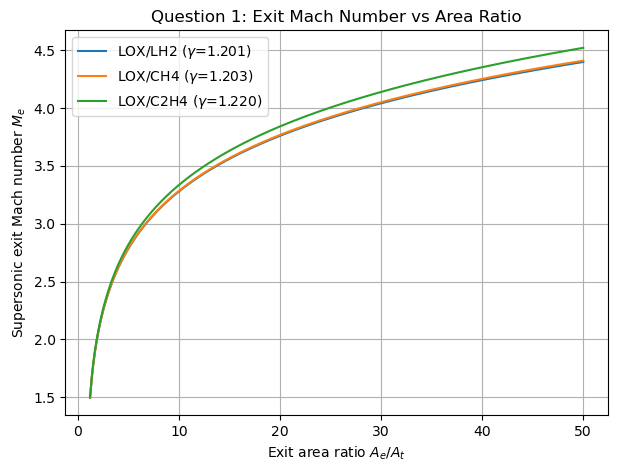

In [21]:
Ae_At_values = np.linspace(1.2, 50.0, 300)

Me_results = {}

plt.figure(figsize=(7, 5))

for label, props in propellant_data.items():
    gamma = props['gamma']
    Me_vals = np.array([mach_from_area_ratio_supersonic(ar, gamma) for ar in Ae_At_values])
    Me_results[label] = Me_vals
    plt.plot(Ae_At_values, Me_vals, label=f"{label} ($\gamma$={gamma:.3f})")

plt.xlabel(r'Exit area ratio $A_e/A_t$')
plt.ylabel(r'Supersonic exit Mach number $M_e$')
plt.title('Question 1: Exit Mach Number vs Area Ratio')
plt.grid(True)
plt.legend()
plt.show()


For a fixed area ratio, the exit Mach number depends only on the value of $\gamma$. Since the Cantera-based values of $\gamma$ are very close for the propellant cases, the curves nearly overlap.

# 2. For each propellant case, use the isentropic nozzle relations to compute exit pressure, exit temperature, exit velocity, and thrust as functions of area ratio over the same range used in Question 1. Plot the results and compare the propellants for sea-level ambient pressure. (3 points)

Use
$$
F = \dot{m}u_e + (p_e-p_{amb})A_e
$$
with the chamber pressure, chamber temperature, and gas properties from Cantera.


### Solution

In [22]:
results_q2 = {}

for label, props in propellant_data.items():
    gamma = props['gamma']
    R = props['R']
    T0 = props['T0']

    Me = []
    Te = []
    pe = []
    ue = []
    mdot = []
    F = []

    for ar in Ae_At_values:
        F_i, mdot_i, Me_i, Te_i, pe_i, ue_i = thrust(ar, At, p0, T0, gamma, R, p_amb)

        Me.append(Me_i)
        Te.append(Te_i)
        pe.append(pe_i)
        ue.append(ue_i)
        mdot.append(mdot_i)
        F.append(F_i)

    results_q2[label] = {
        'Me': np.array(Me),
        'Te': np.array(Te),
        'pe': np.array(pe),
        'ue': np.array(ue),
        'mdot': np.array(mdot),
        'F': np.array(F)
    }

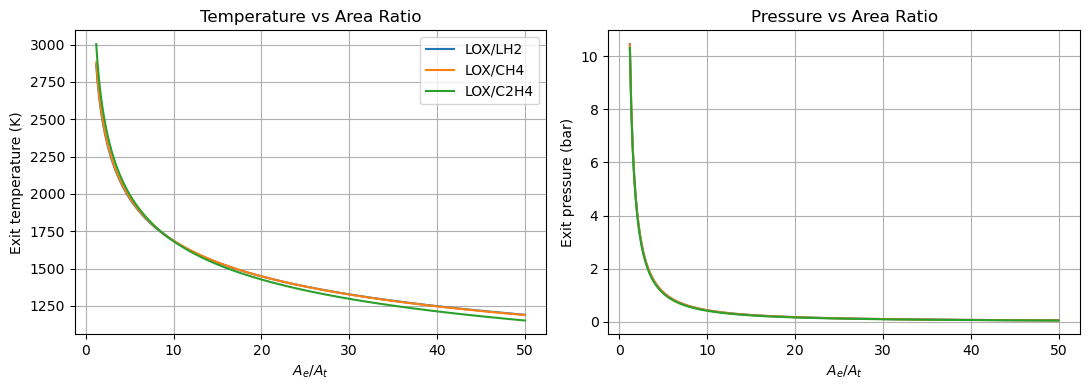

In [23]:
# Plot temperature and pressure
fig, ax = plt.subplots(1, 2, figsize=(11,4))

for label, data in results_q2.items():
    ax[0].plot(Ae_At_values, data['Te'], label=label)
    ax[1].plot(Ae_At_values, data['pe']/1e5, label=label)

# Temperature
ax[0].set_xlabel(r'$A_e/A_t$')
ax[0].set_ylabel('Exit temperature (K)')
ax[0].set_title('Temperature vs Area Ratio')
ax[0].grid()

# Pressure
ax[1].set_xlabel(r'$A_e/A_t$')
ax[1].set_ylabel('Exit pressure (bar)')
ax[1].set_title('Pressure vs Area Ratio')
ax[1].grid()

ax[0].legend()

plt.tight_layout()
plt.show()

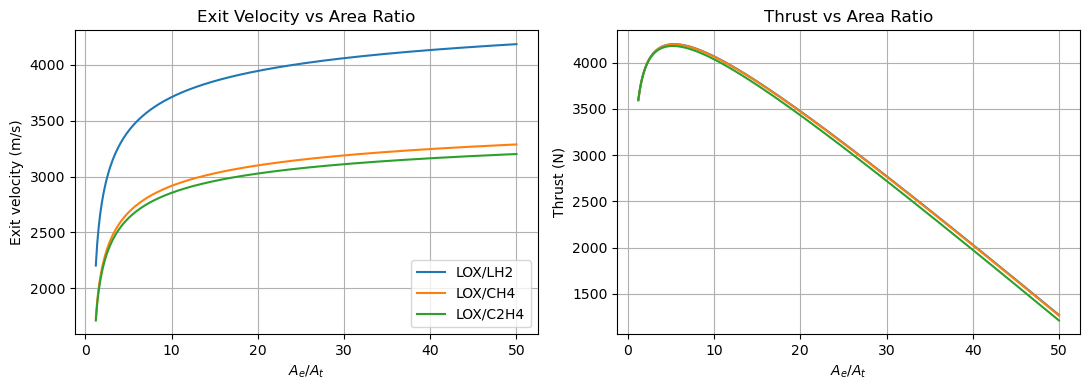

In [24]:
# Plot velocity and thrust
fig, ax = plt.subplots(1, 2, figsize=(11,4))

for label, data in results_q2.items():
    ax[0].plot(Ae_At_values, data['ue'], label=label)
    ax[1].plot(Ae_At_values, data['F'], label=label)

ax[0].set_xlabel(r'$A_e/A_t$')
ax[0].set_ylabel('Exit velocity (m/s)')
ax[0].set_title('Exit Velocity vs Area Ratio')
ax[0].grid()

ax[1].set_xlabel(r'$A_e/A_t$')
ax[1].set_ylabel('Thrust (N)')
ax[1].set_title('Thrust vs Area Ratio')
ax[1].grid()

ax[0].legend()

plt.tight_layout()
plt.show()

As $A_e/A_t$ increases, the exit pressure and exit temperature decrease, while the exit Mach number and exit velocity increase. The thrust does not increase indefinitely at sea level because the pressure term changes as the nozzle becomes more overexpanded or underexpanded. The propellant cases give slightly different thrust levels because they have different chamber temperatures and gas constants.

# 3. Implement a standard-atmosphere model to compute ambient pressure as a function of altitude over the range $0 \leq h \leq 20$ km. Then, for the LOX/CH4 propellant case, calculate nozzle thrust as a function of area ratio at $h = 0,\ 5,\ 10,\ 15,$ and $20$ km. Plot the thrust curves and comment on the trend. (4 points)

Use the same chamber conditions as in Questions 1 and 2.

For the atmosphere model, use the piecewise standard-atmosphere pressure relation
$$
p(h)=p_0\left(1-\frac{Lh}{T_0}\right)^{\frac{g}{RL}} \qquad (0\le h\le 11\text{ km})
$$
and
$$
p(h)=p(11\text{ km})\exp\left[-\frac{g(h-11\text{ km})}{RT}\right] \qquad (11\le h\le 20\text{ km}).
$$

Use the constants: $ p_0 = 101325 Pa, T_0 = 288.15 K, L = 0.0065 K/m, g = 9.81 {m/s}^2, R = 287 J/kgK $


### Solution

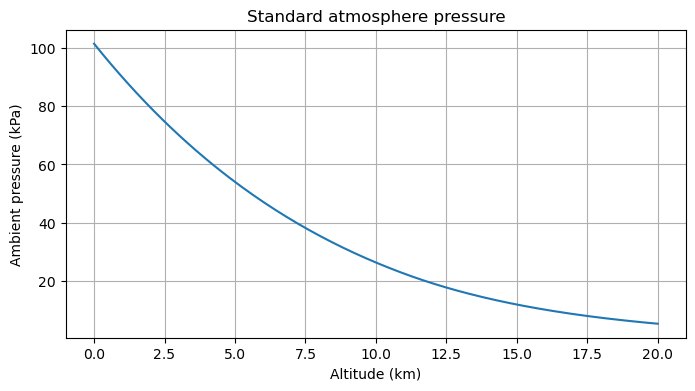

In [25]:
def atmosphere_pressure(h):
    if h <= 11000:
        T = 288.15 - 0.0065 * h
        return 101325 * (T / 288.15) ** (9.80665 / (287.05 * 0.0065))
    else:
        T = 216.65
        p11 = 101325 * (T / 288.15) ** (9.80665 / (287.05 * 0.0065))
        return p11 * np.exp(-9.80665 * (h - 11000) / (287.05 * T))


altitudes = np.linspace(0, 20000, 200)
p_amb_values = np.array([atmosphere_pressure(h) for h in altitudes])

plt.figure(figsize=(8, 4))
plt.plot(altitudes / 1000, p_amb_values / 1000)
plt.xlabel('Altitude (km)')
plt.ylabel('Ambient pressure (kPa)')
plt.title('Standard atmosphere pressure')
plt.grid()
plt.show()


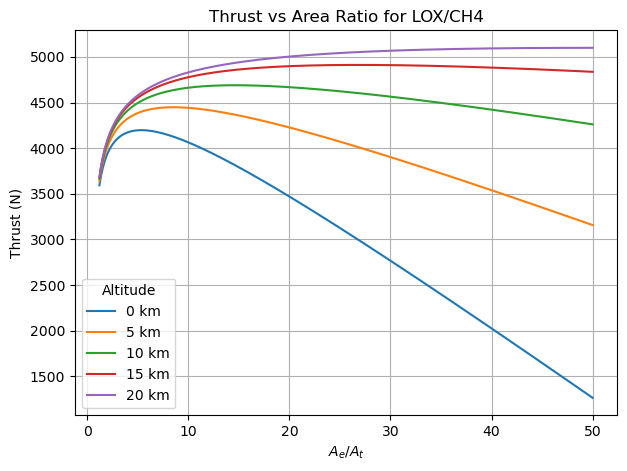

In [26]:
altitudes_plot = [0, 5000, 10000, 15000, 20000]
label = 'LOX/CH4'
props = propellant_data[label]

plt.figure(figsize=(7, 5))

for h in altitudes_plot:
    p_amb_h = atmosphere_pressure(h)
    F_vals = []

    for ar in Ae_At_values:
        F, mdot, Me, Te, pe, ue = thrust(ar, At, p0, props['T0'], props['gamma'], props['R'], p_amb_h)
        F_vals.append(F)

    plt.plot(Ae_At_values, F_vals, label=f'{h/1000:.0f} km')

plt.xlabel(r'$A_e/A_t$')
plt.ylabel('Thrust (N)')
plt.title(f'Thrust vs Area Ratio for {label}')
plt.grid()
plt.legend(title='Altitude')
plt.show()


In [27]:
print('LOX/CH4')
for h in altitudes_plot:
    p_amb_h = atmosphere_pressure(h)
    F_vals = np.array([
        thrust(ar, At, p0, props['T0'], props['gamma'], props['R'], p_amb_h)[0]
        for ar in Ae_At_values
    ])
    i = np.argmax(F_vals)
    print(f'  h = {h/1000:>4.0f} km: max thrust = {F_vals[i]:.2f} N at Ae/At = {Ae_At_values[i]:.3f}')


LOX/CH4
  h =    0 km: max thrust = 4197.61 N at Ae/At = 5.280
  h =    5 km: max thrust = 4448.71 N at Ae/At = 8.544
  h =   10 km: max thrust = 4689.76 N at Ae/At = 14.583
  h =   15 km: max thrust = 4912.20 N at Ae/At = 26.824
  h =   20 km: max thrust = 5099.59 N at Ae/At = 49.837


As altitude increases, the ambient pressure decreases, increasing the pressure-thrust term $F = \dot{m} u_e + (p_e - p_{amb}) A_e .$

Larger exit areas therefore become more beneficial, and the thrust curves shift upward with altitude. The area ratio that produces maximum thrust also increases, since higher-altitude operation favors more complete expansion to the lower ambient pressure.

# 4. The nozzle is ideally expanded when $p_e=p_{amb}$. For each propellant case, determine the design area ratio $A_e/A_t$ required over the altitude range $0 \leq h \leq 20$ km, and plot design area ratio versus altitude on one figure. (3 points)

### Solution

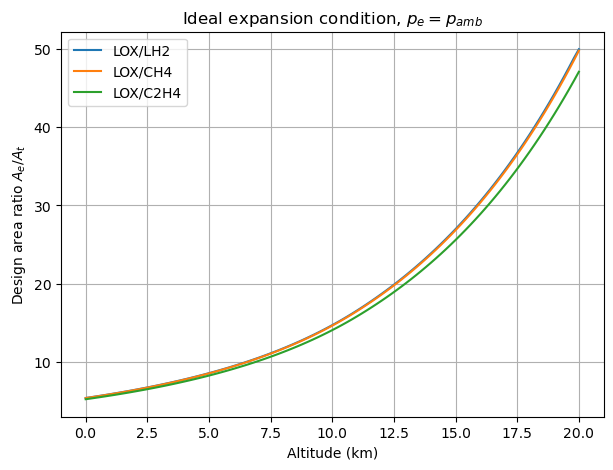

In [28]:
altitudes_q4 = np.linspace(0, 20000, 101)
design_results = {}

for label, props in propellant_data.items():
    pe_curve = np.array([
        exit_state_from_area_ratio(ar, props['gamma'], props['R'], props['T0'], p0)[2]
        for ar in Ae_At_values
    ])

    ar_design = []

    for h in altitudes_q4:
        p_amb_h = atmosphere_pressure(h)
        ar_h = np.interp(p_amb_h, pe_curve[::-1], Ae_At_values[::-1])
        ar_design.append(ar_h)

    design_results[label] = np.array(ar_design)
    
plt.figure(figsize=(7, 5))

for label, ar_vals in design_results.items():
    plt.plot(altitudes_q4 / 1000, ar_vals, label=label)

plt.xlabel('Altitude (km)')
plt.ylabel(r'Design area ratio $A_e/A_t$')
plt.title(r'Ideal expansion condition, $p_e = p_{amb}$')
plt.grid()
plt.legend()
plt.show()


For all three propellant cases, the design area ratio increases strongly with altitude because ideal expansion requires the exit pressure to match the decreasing ambient pressure. The required increase becomes especially large at high altitude, where very low ambient pressure demands much greater expansion. The differences between propellants remain modest, since the design condition depends mainly on the isentropic pressure relation and the Cantera-derived values of $\gamma$ are similar. At 20 km, the required design area ratio is very large for all three cases, showing that a nozzle optimized for high-altitude operation would be poorly matched to sea-level conditions.

# 5. For the LOX/CH4 propellant case, use fixed nozzle area ratios $A_e/A_t = 5$, 15, and 40, and compute thrust over the altitude range $0 \leq h \leq 20$ km. Plot thrust versus altitude for all three area ratios on one figure and compare the performance when the nozzle operates away from its design altitude. (3 points)

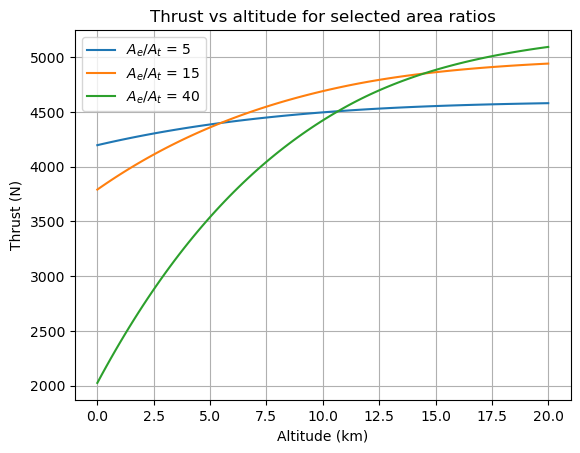

In [29]:
area_ratios = [5, 15, 40]

label = "LOX/CH4"
gamma = propellant_data[label]['gamma']
R = propellant_data[label]['R']
T0 = propellant_data[label]['T0']

altitudes = np.linspace(0, 20, 100)

fig, ax = plt.subplots()

for ar in area_ratios:

    F_vals = []

    for h in altitudes:
        pamb = atmosphere_pressure(h*1000)
        F, mdot, Me, Te, pe, ue = thrust(ar, At, p0, T0, gamma, R, pamb)
        F_vals.append(F)

    ax.plot(altitudes, F_vals, label=f'$A_e/A_t$ = {ar}')

ax.set_xlabel('Altitude (km)')
ax.set_ylabel('Thrust (N)')
ax.set_title('Thrust vs altitude for selected area ratios')
ax.legend()
ax.grid()

plt.show()

The nozzle with Ae/At = 5 produces the highest thrust near sea level, since it is closest to optimal expansion at high ambient pressure. Larger area ratios are overexpanded at low altitude and therefore produce lower thrust. As altitude increases and ambient pressure decreases, the larger area ratios become more favorable and eventually outperform the smaller nozzle. This demonstrates the trade-off between sea-level and high-altitude nozzle design, where a single fixed area ratio cannot be optimal over the full altitude range.

# 6. For the LOX/CH4 propellant case and a large nozzle area ratio of $A_e/A_t$ = 100, compute the fully isentropic thrust and thrust including a normal shock inside the nozzle. Plot both thrust curves versus altitude and compare the results. (4 points)

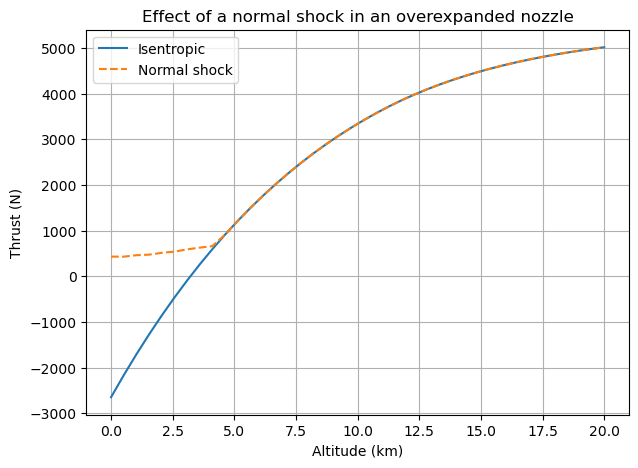

In [30]:
def mach_from_area_ratio_subsonic(A_ratio, gamma, M_grid, A_grid):
    return np.interp(A_ratio, A_grid[::-1], M_grid[::-1])

def normal_shock_relations(M1, gamma):
    M2_sq = (1 + (gamma - 1) / 2 * M1**2) / (gamma * M1**2 - (gamma - 1) / 2)
    M2 = np.sqrt(M2_sq)
    p2_p1 = 1 + 2 * gamma / (gamma + 1) * (M1**2 - 1)
    return M2, p2_p1

def shock_solution(Ae_At, At, p0, T0, gamma, R, p_amb, M_grid_sub, A_grid_sub):
    mdot = throat_mass_flux(p0, T0, gamma, R) * At
    Ae = Ae_At * At

    Me_iso, Te_iso, pe_iso, ue_iso = exit_state_from_area_ratio(Ae_At, gamma, R, T0, p0)
    F_iso = mdot * ue_iso + (pe_iso - p_amb) * Ae

    M2_exit, p2_p1_exit = normal_shock_relations(Me_iso, gamma)
    p_shock_exit = pe_iso * p2_p1_exit

    if p_amb <= p_shock_exit:
        return F_iso, F_iso, None  #not overexpanded

    shock_positions = np.linspace(1.0001, Ae_At, 200)
    pe_values = []
    F_values = []

    for As_At in shock_positions:
        M1 = mach_from_area_ratio_supersonic(As_At, gamma)

        p1 = p0 / (1 + (gamma - 1) / 2 * M1**2) ** (gamma / (gamma - 1))
        M2, p2_p1 = normal_shock_relations(M1, gamma)
        p2 = p1 * p2_p1

        p02 = p2 * (1 + (gamma - 1) / 2 * M2**2) ** (gamma / (gamma - 1))

        As_A2star = area_mach_relation(M2, gamma)
        Ae_A2star = (Ae_At / As_At) * As_A2star

        Me = mach_from_area_ratio_subsonic(Ae_A2star, gamma, M_grid_sub, A_grid_sub)
        Te = T0 / (1 + (gamma - 1) / 2 * Me**2)
        pe = p02 / (1 + (gamma - 1) / 2 * Me**2) ** (gamma / (gamma - 1))
        ue = Me * np.sqrt(gamma * R * Te)

        F = mdot * ue + (pe - p_amb) * Ae

        pe_values.append(pe)
        F_values.append(F)

    pe_values = np.array(pe_values)
    F_values = np.array(F_values)

    idx = np.argmin(np.abs(pe_values - p_amb))
    return F_iso, F_values[idx], shock_positions[idx] 

ar = 100
label = "LOX/CH4"

gamma = propellant_data[label]['gamma']
R = propellant_data[label]['R']
T0 = propellant_data[label]['T0']

# subsonic interpolation grid
M_grid_sub = np.linspace(1e-4, 0.9999, 6000)
A_grid_sub = area_mach_relation(M_grid_sub, gamma)

altitudes = np.linspace(0, 20, 40)

F_iso = []
F_shock = []
shock_location = []

for h in altitudes:
    pamb = atmosphere_pressure(h * 1000)
    F_i, F_s, As_At = shock_solution(ar, At, p0, T0, gamma, R, pamb, M_grid_sub, A_grid_sub)
    F_iso.append(F_i)
    F_shock.append(F_s)

plt.figure(figsize=(7, 5))
plt.plot(altitudes, F_iso, label='Isentropic')
plt.plot(altitudes, F_shock, '--', label='Normal shock')
plt.xlabel('Altitude (km)')
plt.ylabel('Thrust (N)')
plt.title('Effect of a normal shock in an overexpanded nozzle')
plt.legend()
plt.grid()
plt.show()

The plot shows that at low altitude the isentropic solution underpredicts thrust
# due to overexpanded flow, while including a normal shock increases exit pressure and
# thrust. The two curves converge as ambient pressure decreases and the nozzle approaches
# ideal expansion.